In [1]:
import geopandas as gpd
import pyogrio
import xarray as xr

In [2]:
ds = xr.open_zarr("drop_ch_data/harmonized_hru_data.zarr")
ds

<xarray.Dataset> Size: 7GB
Dimensions:                 (hru: 21969, time: 11688)
Coordinates:
  * hru                     (hru) int64 176kB 100001 100002 ... 200111 101461
    x                       (hru) float64 176kB dask.array<chunksize=(21969,), meta=np.ndarray>
    y                       (hru) float64 176kB dask.array<chunksize=(21969,), meta=np.ndarray>
  * time                    (time) datetime64[ns] 94kB 1992-01-01 ... 2023-12-31
Data variables: (12/48)
    agriculture_freq        (hru) float32 88kB dask.array<chunksize=(21969,), meta=np.ndarray>
    area                    (hru) float32 88kB dask.array<chunksize=(21969,), meta=np.ndarray>
    artificial_freq         (hru) float32 88kB dask.array<chunksize=(21969,), meta=np.ndarray>
    aspect_mean             (hru) float32 88kB dask.array<chunksize=(21969,), meta=np.ndarray>
    barren_freq             (hru) float32 88kB dask.array<chunksize=(21969,), meta=np.ndarray>
    bdod_mean               (hru) float32 88kB dask.array<chunksize=(21969,), meta=np.ndarray>
    ...                      ...
    slope_min               (hru) float32 88kB dask.array<chunksize=(21969,), meta=np.ndarray>
    storage_level           (hru) float32 88kB dask.array<chunksize=(21969,), meta=np.ndarray>
    tair                    (time, hru) float32 1GB dask.array<chunksize=(366, 1374), meta=np.ndarray>
    upstream_area           (hru) float32 88kB dask.array<chunksize=(21969,), meta=np.ndarray>
    water_freq              (hru) float32 88kB dask.array<chunksize=(21969,), meta=np.ndarray>
    wetlands_freq           (hru) float32 88kB dask.array<chunksize=(21969,), meta=np.ndarray>
Attributes:
    title:            Harmonized HRU dataset for DROP
    author:           Basil Kraft
    institution:      ETH Zurich
    source:           Harmonized from third-party data; see the `source` and ...
    comment:          Data aggregated to hydrological drainage units (HRUs) c...
    references:       Kraft, B., et al.: DROP: A scalable deep learning appro...
    license:          Open Database License (ODbL) 1.0, https://opendatacommo...
    acknowledgement:  Contains modified data from the sources listed in the `...
    history:          Created with project/scripts/preprocessing.py of https:...

In [12]:
hrus = gpd.read_file("drop_ch_data/hrus.gpkg").set_index("EZGNR")  # EZGNR is the HRU ID, `hru` in the dataset
metadata = pyogrio.read_info("drop_ch_data/hrus.gpkg")["layer_metadata"]
print(metadata["description_EZGNR"])

HRU ID, as `hru` in the dataset. Source: FOEN; CAMELS-CH outside of Switzerland.


In [ ]:
# Which variables are available?
list(ds.data_vars)

# What does precipitation mean, and what are its units?
ds["prec"].attrs

{'long_name': 'Precipitation',
 'units': 'mm d-1',
 'source': 'MeteoSwiss: RhiresD',
 'references': '1) Schwarb, M.: The alpine precipitation climate: evaluation of a high-resolution analysis scheme using comprehensive rain-gauge data, Doctoral Thesis, ETH Zurich, https://doi.org/10.3929/ethz-a-004121274, 2000. 2) MeteoSwiss: Daily Precipitation (final analysis): RhiresD, https://www.meteoschweiz.admin.ch/dam/jcr:4f51f0f1-0fe3-48b5-9de0-15666327e63c/ProdDoc_RhiresD.pdf, last access: 1 April 2024, 2021.'}

In [7]:
# Which dimensions does it have?
ds["prec"].dims

('time', 'hru')

In [8]:
hru = ds.sel(hru=145830)

hru[[
    "area",
    "upstream_area",
    "downstream",
    "height_mean",
    "agriculture_freq",
    "has_obs",
]].compute()

<xarray.Dataset> Size: 45B
Dimensions:           ()
Coordinates:
    hru               int64 8B 145830
    x                 float64 8B 2.66e+06
    y                 float64 8B 1.263e+06
Data variables:
    area              float32 4B 0.9654
    upstream_area     float32 4B 1.755e+04
    downstream        int32 4B 199304
    height_mean       float32 4B 351.3
    agriculture_freq  float32 4B 0.7181
    has_obs           bool 1B True
Attributes:
    title:            Harmonized HRU dataset for DROP
    author:           Basil Kraft
    institution:      ETH Zurich
    source:           Harmonized from third-party data; see the `source` and ...
    comment:          Data aggregated to hydrological drainage units (HRUs) c...
    references:       Kraft, B., et al.: DROP: A scalable deep learning appro...
    license:          Open Database License (ODbL) 1.0, https://opendatacommo...
    acknowledgement:  Contains modified data from the sources listed in the `...
    history:          Created with project/scripts/preprocessing.py of https:...

In [9]:
flood = hru[[
    "prec",
    "tair",
    "Q_obs_m3s",
    "q_prevah_m3s",
]].sel(time=slice("2007-08-01", "2007-08-20"))

flood.to_dataframe()

,prec,tair,Q_obs_m3s,q_prevah_m3s,hru,x,y
time,,,,,,,
2007-08-01,1.495514,17.188488,779.059937,0.003145,145830,2.659793e+06,1.262605e+06
2007-08-02,2.624521,18.119093,756.515686,0.003077,145830,2.659793e+06,1.262605e+06
2007-08-03,0.392875,16.981293,857.202271,0.003012,145830,2.659793e+06,1.262605e+06
2007-08-04,0.000000,18.012196,813.660400,0.002941,145830,2.659793e+06,1.262605e+06
2007-08-05,0.000000,20.200047,736.380005,0.002873,145830,2.659793e+06,1.262605e+06
2007-08-06,0.000000,22.412142,684.777893,0.002806,145830,2.659793e+06,1.262605e+06
2007-08-07,16.424454,18.867796,725.098267,0.002798,145830,2.659793e+06,1.262605e+06
2007-08-08,63.877834,14.567582,1287.582886,0.010786,145830,2.659793e+06,1.262605e+06
2007-08-09,3.948119,11.957395,2374.935059,0.017916,145830,2.659793e+06,1.262605e+06


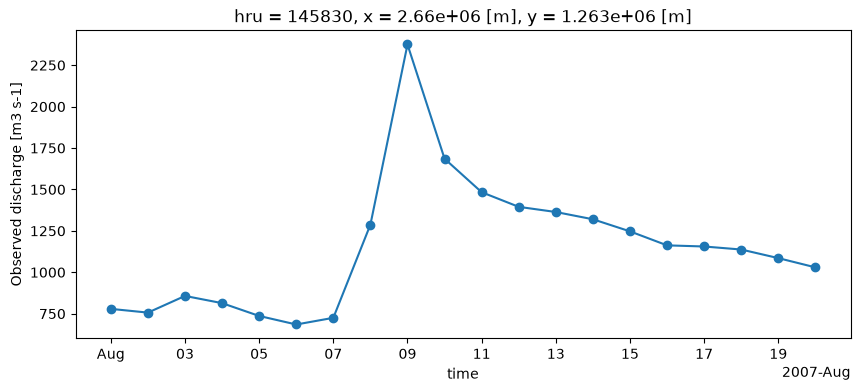

In [13]:
flood["Q_obs_m3s"].plot(
    figsize=(10, 4),
    marker="o",
)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

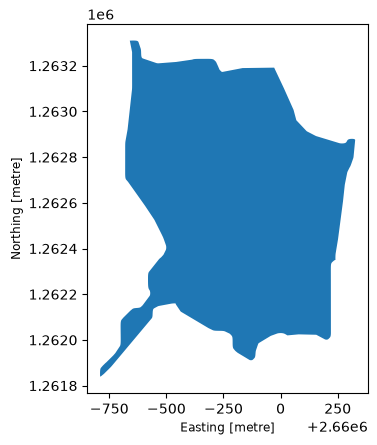

In [14]:
import geopandas as gpd

hrus = gpd.read_file(
    "drop_ch_data/hrus.gpkg",
    layer="hrus",
).set_index("EZGNR")

hrus.loc[[145830]].plot()

In [15]:
pred = xr.open_zarr(
    "drop_ch_data/outputs/predictions_combined.zarr"
)

pred.model.values

array(['instant_random', 'instant_hard', 'lumped_random', 'lumped_hard',
       'routed_random', 'routed_hard'], dtype=StringDType())

<Axes: xlabel='time', ylabel='Discharge [m³/s]'>

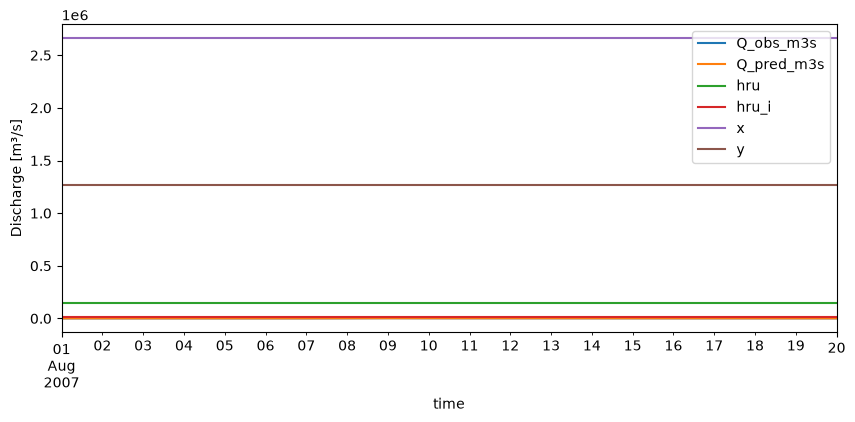

In [16]:
example = pred.sel(
    model="routed_random",
    hru=145830,
    time=slice("2007-08-01", "2007-08-20"),
)

example[["Q_obs_m3s", "Q_pred_m3s"]].to_dataframe().plot(
    figsize=(10, 4),
    ylabel="Discharge [m³/s]",
)

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr

pred = xr.open_zarr(
    "drop_ch_data/outputs/predictions_combined.zarr"
)

event = pred.sel(
    hru=145830,
    time=slice("2007-08-01", "2007-08-20"),
)

comparison = pd.DataFrame({
    "Observed": event["Q_obs_m3s"].to_series(),
    "DROP routed": event["Q_pred_m3s"]
        .sel(model="routed_random").to_series(),
    "Lumped LSTM": event["Q_pred_m3s"]
        .sel(model="lumped_random").to_series(),
})

ax = comparison.plot(
    figsize=(11, 4),
    style=["-o", "--s", "-.^"],
    color=["#000000", "#0072B2", "#E69F00"],
)
ax.lines[0].set_linewidth(2.5)
ax.set(
    title="Aare, HRU 145830 — August 2007 flood",
    xlabel="Date",
    ylabel="Daily mean discharge [m³/s]",
)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
routing_comparison = pd.DataFrame({
    "Observed": event["Q_obs_m3s"].to_series(),
    "With learned routing": event["Q_pred_m3s"]
        .sel(model="routed_random").to_series(),
    "Same runoff, instantaneous accumulation":
        event["Q_instant_pred_m3s"]
        .sel(model="routed_random").to_series(),
})

ax = routing_comparison.plot(
    figsize=(11, 4),
    style=["-o", "--s", "-.^"],
    color=["#000000", "#0072B2", "#666666"],
)
ax.lines[0].set_linewidth(2.5)
ax.set(
    title="Effect of routing — same runoff model",
    xlabel="Date",
    ylabel="Daily mean discharge [m³/s]",
)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Further analyses: one gauge, two spatial splits
These cells read the published predictions; they do not train or modify a model. Run them in order from the project root. Only the selected HRU and dates are loaded. Change `analysis_hru` to explore another gauged HRU.

The spatial label **training** does not mean every date was used in training. Likewise, the `hard` split is not automatically held out at every HRU. The table below reports the actual spatial assignment. These exploratory summaries are not a reproduction of the paper's evaluation protocol.

Colors remain consistent: observations black, routed DROP blue, lumped LSTM orange, instantaneous baseline gray. Line styles also distinguish the series: observations solid, routed dashed, lumped dash-dot, instantaneous dotted. Event and seasonal plots use circles, squares, triangles, and diamonds respectively. Separate panels compare the random and hard splits.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from IPython.display import display

analysis_pred = xr.open_zarr("drop_ch_data/outputs/predictions_combined.zarr")
analysis_hru = 145830
analysis_period = ("2000-01-01", "2022-12-31")
analysis_event = ("2007-08-01", "2007-08-20")
analysis_models = [
    "routed_random", "routed_hard",
    "lumped_random", "lumped_hard",
    "instant_random", "instant_hard",
]
analysis_colors = {"routed": "#0072B2", "lumped": "#E69F00", "instant": "#666666"}
analysis_linestyles = {"routed": "--", "lumped": "-.", "instant": ":"}
analysis_markers = {"routed": "s", "lumped": "^", "instant": "D"}
subset_names = {0: "Unused", 1: "Training", 2: "Validation", 3: "Test"}

# Build one table of comparable discharge series, with a shared daily index.
# For the published instant models, use the documented instantaneous sum.
def discharge_table(hru_id, dates):
    selected = analysis_pred.sel(hru=hru_id, time=slice(*dates))
    columns = {"Observed": selected["Q_obs_m3s"].to_series()}
    for model in analysis_models:
        variable = "Q_instant_pred_m3s" if model.startswith("instant_") else "Q_pred_m3s"
        columns[model] = selected[variable].sel(model=model).to_series()
    return pd.DataFrame(columns).replace([np.inf, -np.inf], np.nan)

if not bool(analysis_pred["has_obs"].sel(hru=analysis_hru).compute().item()):
    raise ValueError("Select a gauged HRU (has_obs=True) for observation comparisons.")

assignments = analysis_pred["subset"].sel(hru=analysis_hru, model=analysis_models).compute()
assignment_table = pd.DataFrame({
    "Model": analysis_models,
    "Spatial subset": [subset_names.get(int(v), "Unknown") for v in assignments.values],
}).set_index("Model")
display(assignment_table)

# Candidate gauges held out in BOTH the routed and lumped hard experiments.
# This avoids presenting a training gauge as an unseen-catchment evaluation.
candidates = analysis_pred["has_obs"] & (analysis_pred["subset"].sel(model="routed_hard") == 3)
candidates = candidates & (analysis_pred["subset"].sel(model="lumped_hard") == 3)
held_out_hrus = analysis_pred.hru.values[candidates.compute().values]
print("First candidate HRUs held out in both hard experiments:", held_out_hrus[:15])
print("Current HRU:", analysis_hru)
print("Instant baselines use Q_instant_pred_m3s; other models use Q_pred_m3s.")

,Spatial subset
Model,
routed_random,Training
routed_hard,Training
lumped_random,Training
lumped_hard,Training
instant_random,Training
instant_hard,Training


First candidate HRUs held out in both hard experiments: [220013 102108 102532 102630 102733 106106 106798 109350 111622 113056
 117499 123575 134565 135018 141936]
Current HRU: 145830
Instant baselines use Q_instant_pred_m3s; other models use Q_pred_m3s.


## 1. Flood magnitude, timing, and volume
Compare the same event window and the same valid days across all six models. Peak error is relative to the observed maximum; timing error is positive for a later peak. Volume is the sum of **daily mean discharge × 86,400 seconds**, not an hourly peak estimate. It is total river flow through the window, not harvestable water. A fixed window can omit water delayed beyond its end.

Common valid days: 20 / 20


,Peak [m³/s],Peak date,Peak error [%],Peak timing error [days],Window volume [million m³],Volume error [%]
Series,,,,,,
Observed,2374.939941,2007-08-09,0.000000,0,1994.140015,0.00
routed_random,2001.040039,2007-08-09,-15.740000,0,1922.550049,-3.59
routed_hard,2197.260010,2007-08-09,-7.480000,0,1985.359985,-0.44
lumped_random,3185.909912,2007-08-09,34.150002,0,1926.829956,-3.37
lumped_hard,3603.060059,2007-08-09,51.709999,0,2014.670044,1.03
instant_random,4047.830078,2007-08-09,70.440002,0,1906.510010,-4.39
instant_hard,3828.159912,2007-08-08,61.189999,-1,1854.219971,-7.02


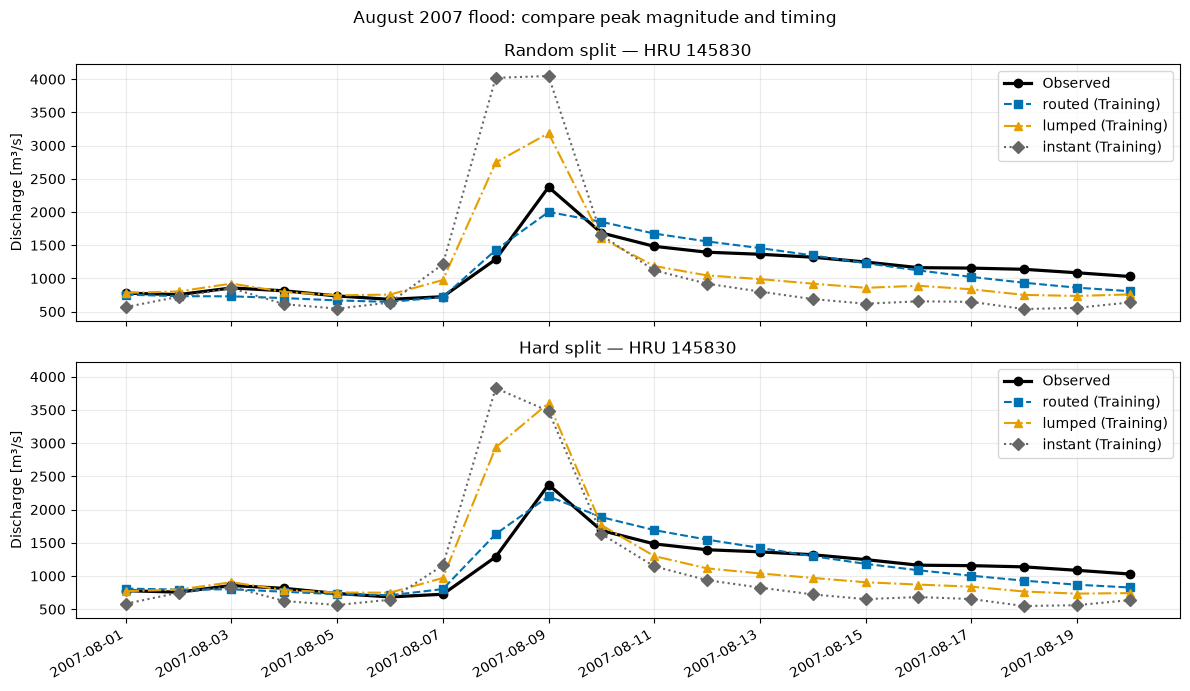

In [24]:
event_discharge = discharge_table(analysis_hru, analysis_event)
event_common = event_discharge.dropna()
if len(event_common) < 2:
    raise ValueError("Insufficient common event data; choose another HRU or event.")
print(f"Common valid days: {len(event_common)} / {len(event_discharge)}")
obs_event = event_common["Observed"]
obs_peak = obs_event.max()
obs_peak_date = obs_event.idxmax()
obs_volume = obs_event.sum() * 86400 / 1e6
rows = []
for name in event_common.columns:
    flow = event_common[name]
    rows.append({
        "Series": name,
        "Peak [m³/s]": flow.max(),
        "Peak date": flow.idxmax().date(),
        "Peak error [%]": 100 * (flow.max() / obs_peak - 1) if obs_peak > 0 else np.nan,
        "Peak timing error [days]": (flow.idxmax() - obs_peak_date).days,
        "Window volume [million m³]": flow.sum() * 86400 / 1e6,
        "Volume error [%]": 100 * ((flow.sum() * 86400 / 1e6) / obs_volume - 1) if obs_volume > 0 else np.nan,
    })
event_summary = pd.DataFrame(rows).set_index("Series")
display(event_summary.round(2))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True)
for ax, split in zip(axes, ["random", "hard"]):
    ax.plot(event_discharge.index, event_discharge["Observed"], color="black", marker="o", label="Observed", linewidth=2.3)
    for family, color in analysis_colors.items():
        name = f"{family}_{split}"
        ax.plot(event_discharge.index, event_discharge[name], color=color, linestyle=analysis_linestyles[family], marker=analysis_markers[family],
                label=f"{family} ({assignment_table.loc[name, 'Spatial subset']})")
    ax.set(title=f"{split.capitalize()} split — HRU {analysis_hru}", ylabel="Discharge [m³/s]")
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle("August 2007 flood: compare peak magnitude and timing")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 2. Event residuals: when does each model miss?
Residual = predicted minus observed discharge. Values above zero are overestimates; values below zero are underestimates. The common vertical scale makes the two splits comparable. Gaps remain gaps rather than being filled or interpolated.

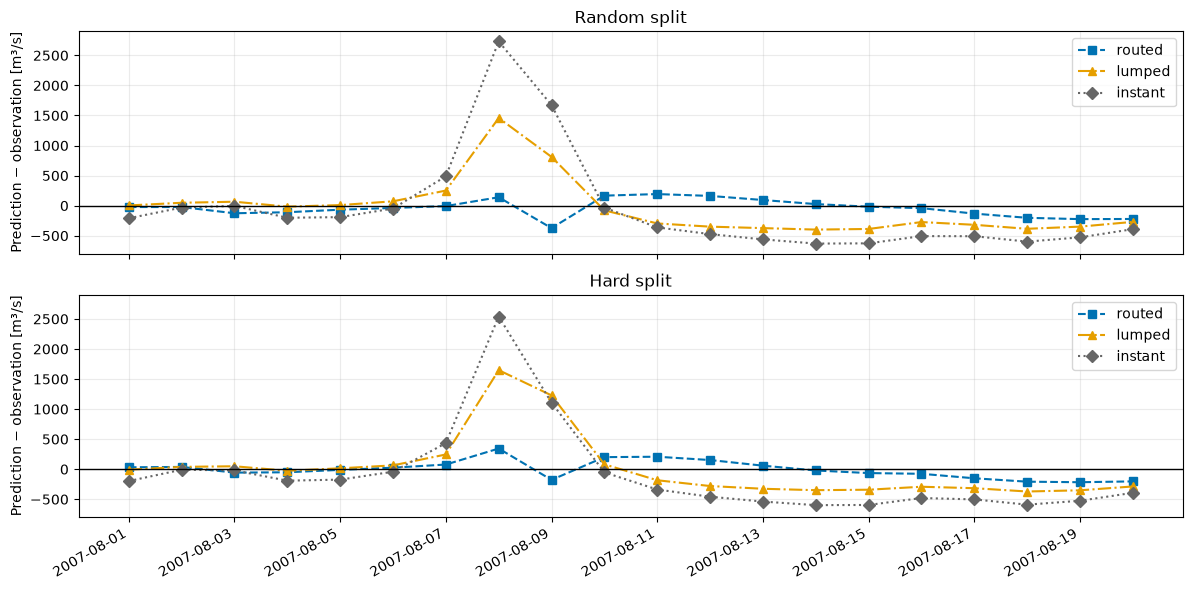

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, split in zip(axes, ["random", "hard"]):
    for family, color in analysis_colors.items():
        name = f"{family}_{split}"
        error = event_discharge[name] - event_discharge["Observed"]
        ax.plot(error.index, error, color=color, linestyle=analysis_linestyles[family], marker=analysis_markers[family], label=family)
    ax.axhline(0, color="black", linewidth=1)
    ax.set(title=f"{split.capitalize()} split", ylabel="Prediction − observation [m³/s]")
    ax.grid(alpha=0.25)
    ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 3. Longer-period skill and flow-duration curves
The event above is just one flood. Here we compare 2000–2022, using **exactly the same valid days for every series**. This window is exploratory; it is not labelled an independent temporal test period.

- **NSE:** 1 is perfect; 0 equals using the observed mean; negative values are worse than that reference.
- **KGE (original form):** combines correlation, variability ratio, and mean-flow ratio; 1 is perfect. Interpret its components too.
- **RMSE:** typical error magnitude with more weight on large errors, in m³/s.
- **Volume bias:** relative difference in cumulative flow; positive means excess predicted water.

A flow-duration curve sorts flows from high to low. It shows how often a discharge is exceeded, but discards event timing. Logarithmic axes below exclude zero or negative flows.

Common valid days: 8401 / 8401


,Spatial subset,Days,NSE,KGE,Correlation,Variability ratio,Mean-flow ratio,RMSE [m³/s],Volume bias [%]
Model,,,,,,,,,
routed_random,Training,8401,0.871,0.845,0.963,0.897,0.890,92.893997,-10.991
routed_hard,Training,8401,0.896,0.838,0.963,0.859,0.930,83.513000,-6.966
lumped_random,Training,8401,0.785,0.812,0.892,0.853,0.953,120.026001,-4.724
lumped_hard,Training,8401,0.743,0.827,0.887,0.914,0.901,131.153000,-9.880
instant_random,Training,8401,0.576,0.772,0.833,1.135,0.922,168.378006,-7.778
instant_hard,Training,8401,0.615,0.801,0.838,1.090,0.928,160.434998,-7.174


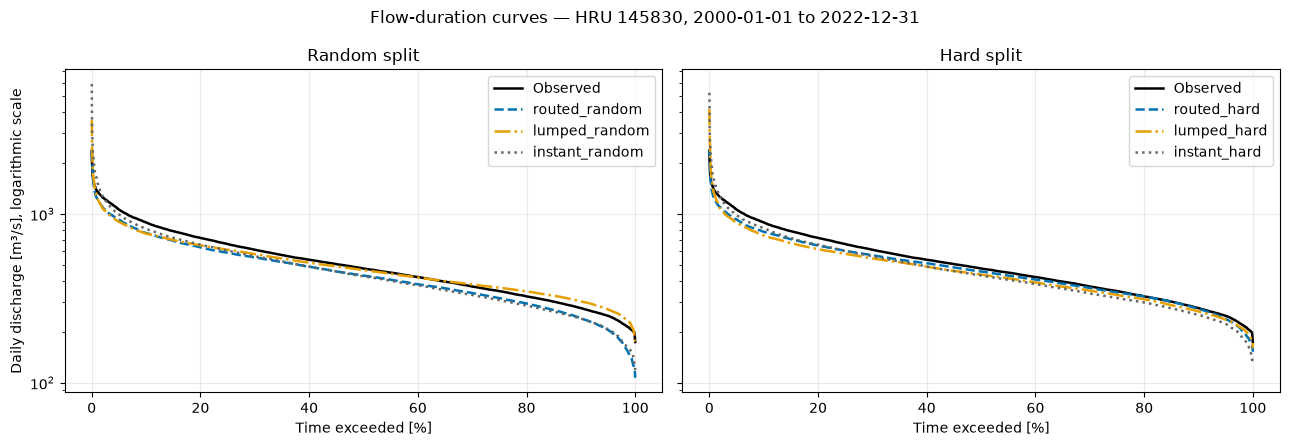

In [26]:
period_discharge = discharge_table(analysis_hru, analysis_period)
period_common = period_discharge.dropna()
if len(period_common) < 3:
    raise ValueError("Insufficient common data for the selected period.")
print(f"Common valid days: {len(period_common)} / {len(period_discharge)}")
observed = period_common["Observed"]
rows = []
for name in analysis_models:
    simulated = period_common[name]
    error = simulated - observed
    correlation = simulated.corr(observed)
    variability_ratio = simulated.std(ddof=0) / observed.std(ddof=0) if observed.std(ddof=0) > 0 else np.nan
    mean_ratio = simulated.mean() / observed.mean() if observed.mean() != 0 else np.nan
    denominator = ((observed - observed.mean()) ** 2).sum()
    rows.append({
        "Model": name,
        "Spatial subset": assignment_table.loc[name, "Spatial subset"],
        "Days": len(period_common),
        "NSE": 1 - (error ** 2).sum() / denominator if denominator > 0 else np.nan,
        "KGE": 1 - np.sqrt((correlation - 1)**2 + (variability_ratio - 1)**2 + (mean_ratio - 1)**2),
        "Correlation": correlation,
        "Variability ratio": variability_ratio,
        "Mean-flow ratio": mean_ratio,
        "RMSE [m³/s]": np.sqrt((error ** 2).mean()),
        "Volume bias [%]": 100 * (mean_ratio - 1),
    })
period_metrics = pd.DataFrame(rows).set_index("Model")
display(period_metrics.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, split in zip(axes, ["random", "hard"]):
    for name in ["Observed"] + [f"{family}_{split}" for family in analysis_colors]:
        ordered = np.sort(period_common[name].to_numpy())[::-1]
        exceedance = 100 * np.arange(1, len(ordered) + 1) / (len(ordered) + 1)
        positive = ordered > 0
        color = "black" if name == "Observed" else analysis_colors[name.split("_")[0]]
        ax.plot(exceedance[positive], ordered[positive], color=color, linestyle="-" if name == "Observed" else analysis_linestyles[name.split("_")[0]], label=name, linewidth=1.8)
    ax.set(yscale="log", xlabel="Time exceeded [%]", title=f"{split.capitalize()} split")
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Daily discharge [m³/s], logarithmic scale")
fig.suptitle(f"Flow-duration curves — HRU {analysis_hru}, {analysis_period[0]} to {analysis_period[1]}")
fig.tight_layout()
plt.show()

## 4. Seasonal behaviour and observed-versus-predicted flow
Monthly means below pool all common valid days by calendar month across the selected years: this is the average seasonal cycle, not one individual year. Scatter plots show routed DROP against observations; the diagonal is perfect agreement. Equal x/y scales prevent visual distortion.

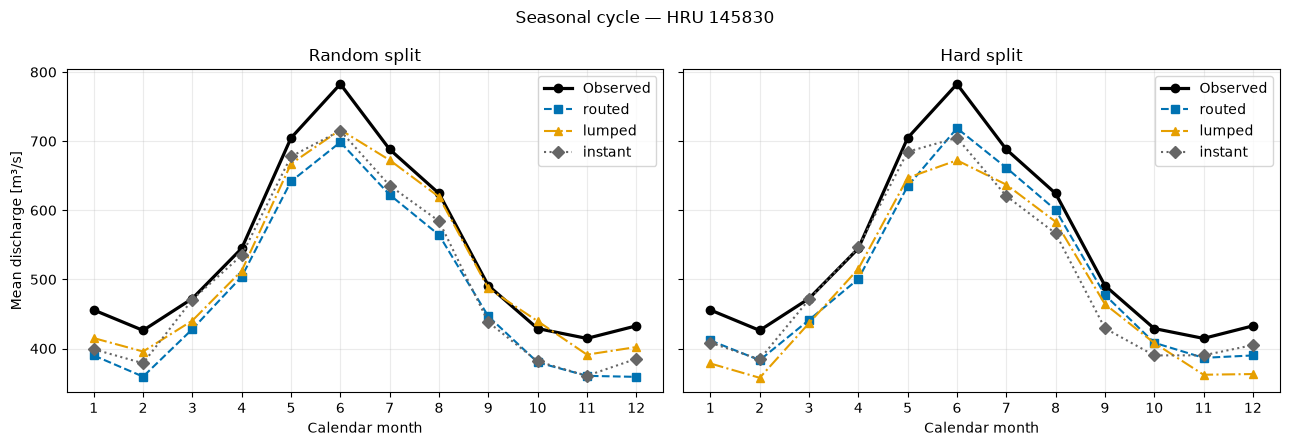

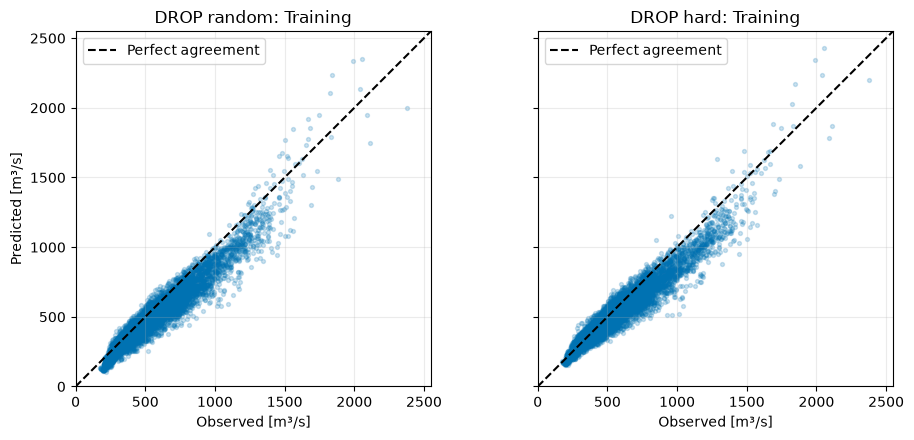

In [27]:
monthly_cycle = period_common.groupby(period_common.index.month).mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, split in zip(axes, ["random", "hard"]):
    ax.plot(monthly_cycle.index, monthly_cycle["Observed"], color="black", marker="o", label="Observed", linewidth=2.3)
    for family, color in analysis_colors.items():
        name = f"{family}_{split}"
        ax.plot(monthly_cycle.index, monthly_cycle[name], color=color, linestyle=analysis_linestyles[family], marker=analysis_markers[family], label=family)
    ax.set(xticks=range(1, 13), xlabel="Calendar month", title=f"{split.capitalize()} split")
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Mean discharge [m³/s]")
fig.suptitle(f"Seasonal cycle — HRU {analysis_hru}")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
limit = 1.05 * period_common[["Observed", "routed_random", "routed_hard"]].max().max()
for ax, split in zip(axes, ["random", "hard"]):
    name = f"routed_{split}"
    ax.scatter(observed, period_common[name], color=analysis_colors["routed"], s=8, alpha=0.2, rasterized=True)
    ax.plot([0, limit], [0, limit], color="black", linestyle="--", label="Perfect agreement")
    ax.set(xlim=(0, limit), ylim=(0, limit), aspect="equal", xlabel="Observed [m³/s]",
           title=f"DROP {split}: {assignment_table.loc[name, 'Spatial subset']}")
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Predicted [m³/s]")
fig.tight_layout()
plt.show()

## 5. Exploratory floodwater volume above a threshold
This is a **diagnostic of existing discharge series**, not a reservoir extension or an estimate of feasible irrigation supply. For each threshold, we sum `max(Q − threshold, 0) × 86,400` over the common event days. The thresholds are illustrative, not ecological or operational limits. No storage capacity, diversion limit, evaporation, downstream feedback, or irrigation demand is represented. Daily means cannot recover subdaily flood peaks.

The curves show how differences in predicted floods propagate into estimated above-threshold volume. They are useful for assessing sensitivity before choosing a harvesting method.

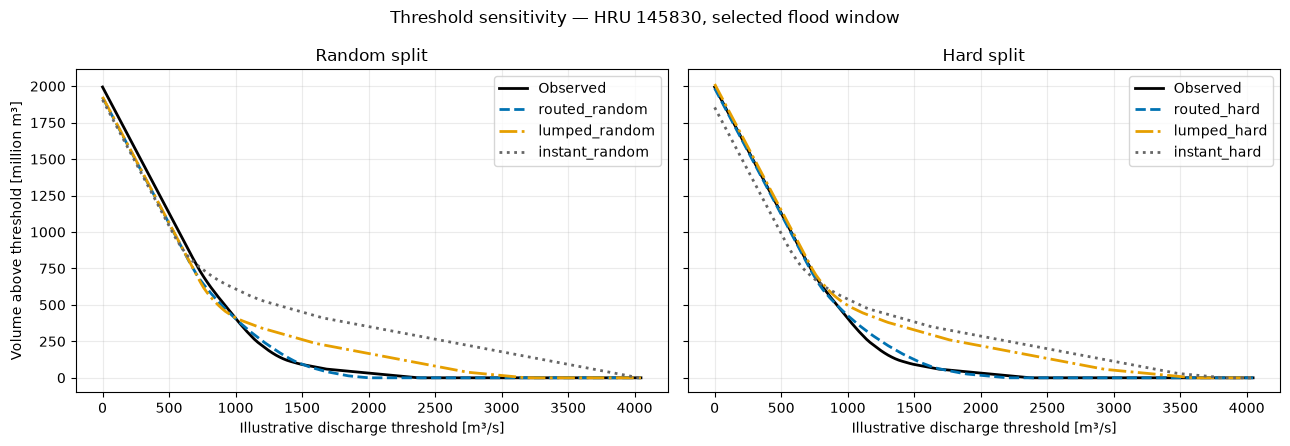

In [28]:
thresholds = np.linspace(0, event_common.max().max(), 150)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, split in zip(axes, ["random", "hard"]):
    for name in ["Observed"] + [f"{family}_{split}" for family in analysis_colors]:
        discharge = event_common[name].to_numpy()
        excess_volume = np.maximum(discharge[:, None] - thresholds[None, :], 0).sum(axis=0) * 86400 / 1e6
        color = "black" if name == "Observed" else analysis_colors[name.split("_")[0]]
        ax.plot(thresholds, excess_volume, color=color, linestyle="-" if name == "Observed" else analysis_linestyles[name.split("_")[0]], label=name, linewidth=2)
    ax.set(xlabel="Illustrative discharge threshold [m³/s]", title=f"{split.capitalize()} split")
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Volume above threshold [million m³]")
fig.suptitle(f"Threshold sensitivity — HRU {analysis_hru}, selected flood window")
fig.tight_layout()
plt.show()

## Nationwide CPU run: predictions for 2007
This section analyses **our new inference run**, rather than the supplied results. It is self-contained: run from this heading downward with the project root as working directory. The model used the `routed/random` checkpoint, 2006 for 365 days of warm-up, and 2007 for saved predictions. No training was performed.

Keep three questions separate: (1) did every HRU receive usable predictions, (2) how do predictions match observations at gauges, and (3) how closely do they reproduce the supplied predictions? One year cannot establish general model skill. Training/validation/test labels refer to the original **spatial** split, not necessarily an independent time period.

Color conventions: observations black solid, new predictions blue dashed, published predictions orange dash-dot; use markers as well as color. Local runoff in our output is called `q_local_pred_m3s` to avoid macOS's case-insensitive collision with `Q_pred_m3s`. Do not sum discharge across all HRUs: the same water passes through multiple downstream locations.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from IPython.display import display

national_path = Path("outputs_local/routed_random_all_2007/preds.zarr")
national_run = xr.open_zarr(national_path)
national_inputs = xr.open_zarr("drop_ch_data/harmonized_hru_data.zarr")
national_published = xr.open_zarr("drop_ch_data/outputs/predictions_combined.zarr")
national_year = "2007"
national_labels = {0: "Unused", 1: "Training", 2: "Validation", 3: "Test"}
required = {"Q_pred_m3s", "q_local_pred_m3s", "subset"}
if not required.issubset(national_run.data_vars):
    raise ValueError("Incomplete output or wrong run directory: missing required variables.")

# Read only discharge for the saved year, not every variable for both years.
national_q = national_run.Q_pred_m3s.sel(time=national_year).compute()
if national_q.sizes["time"] != 365:
    raise ValueError("Expected 365 daily predictions for 2007.")
covered = np.isfinite(national_q).all("time")
input_ids = set(national_inputs.hru.values.tolist())
output_ids = set(national_run.hru.values.tolist())
coverage_summary = pd.Series({
    "Expected HRUs": len(input_ids),
    "Output HRUs": len(output_ids),
    "HRUs missing from output": len(input_ids - output_ids),
    "Unexpected HRUs": len(output_ids - input_ids),
    "HRUs with finite predictions on all 365 days": int(covered.sum()),
    "Nonfinite HRU-days": int((~np.isfinite(national_q)).sum()),
    "Negative discharge HRU-days": int((national_q < 0).sum()),
    "Warm-up discharge values present (expected 0)": int(national_run.Q_pred_m3s.sel(time="2006").notnull().sum().compute()),
})
display(coverage_summary.to_frame("Count"))
print("Smallest/largest daily discharge across HRUs:", float(national_q.min()), float(national_q.max()), "m³/s")
if input_ids != output_ids or not bool(covered.all()) or bool((national_q < 0).any()):
    raise ValueError("Coverage or discharge validity check failed; inspect before interpreting skill.")

### Gauge performance: keep spatial test gauges separate
Only gauged HRUs can be evaluated against observations. At each gauge, metrics use paired finite daily values. Gauges with fewer than 300 paired days are reported but excluded from the summary and figures; the observation threshold is adjustable. Constant-flow observations also make NSE/KGE undefined.

NSE and original KGE are best at 1. RMSE is in m³/s and depends strongly on river size. Volume bias is positive when cumulative predicted discharge exceeds the observed cumulative discharge **over the available paired days**. These per-gauge volumes must not be summed across nested catchments.

In [ ]:
minimum_paired_days = 300
national_gauge_ids = national_inputs.hru.values[national_inputs.has_obs.compute().values.astype(bool)]
national_obs = national_inputs.Q_obs_m3s.sel(hru=national_gauge_ids, time=national_year).compute()
national_sim = national_q.sel(hru=national_gauge_ids)
national_rows = []
for hru_id in national_gauge_ids:
    observed = national_obs.sel(hru=hru_id).values
    simulated = national_sim.sel(hru=hru_id).values
    valid = np.isfinite(observed) & np.isfinite(simulated)
    obs, sim = observed[valid].astype(float), simulated[valid].astype(float)
    row = {"hru": int(hru_id), "Spatial subset": national_labels.get(int(national_run.subset.sel(hru=hru_id).compute()), "Unknown"), "Paired days": len(obs)}
    row.update({"NSE": np.nan, "KGE": np.nan, "RMSE [m³/s]": np.nan, "Volume bias [%]": np.nan})
    if len(obs) >= 2:
        error = sim - obs
        variance = ((obs - obs.mean())**2).sum()
        row["RMSE [m³/s]"] = np.sqrt(np.mean(error**2))
        if variance > 0:
            row["NSE"] = 1 - np.sum(error**2) / variance
        if obs.mean() != 0:
            beta = sim.mean() / obs.mean()
            row["Volume bias [%]"] = 100 * (beta - 1)
            if obs.std() > 0 and sim.std() > 0:
                correlation = np.corrcoef(obs, sim)[0, 1]
                alpha = sim.std() / obs.std()
                row["KGE"] = 1 - np.sqrt((correlation-1)**2 + (alpha-1)**2 + (beta-1)**2)
    national_rows.append(row)
national_metrics = pd.DataFrame(national_rows).set_index("hru")
national_metrics["Enough paired days"] = national_metrics["Paired days"] >= minimum_paired_days
national_eligible = national_metrics.loc[national_metrics["Enough paired days"]]
print(f"Gauges: {len(national_metrics)}; at least {minimum_paired_days} paired days: {len(national_eligible)}")
display(national_metrics.groupby("Spatial subset").agg(
    Gauges=("Paired days", "size"),
    Eligible=("Enough paired days", "sum"),
))
print("Median metrics over eligible gauges (each gauge gets equal weight):")
display(national_eligible.groupby("Spatial subset")[["NSE", "KGE", "RMSE [m³/s]", "Volume bias [%]"]].median().round(3))
print("Held-out spatial test gauges with the lowest NSE — diagnostic, not a national ranking:")
display(national_eligible.query("`Spatial subset` == 'Test'").sort_values("NSE").head(10).round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["NSE", "KGE", "Volume bias [%]"]):
    subsets = [s for s in ["Training", "Validation", "Test"] if len(national_eligible.loc[national_eligible["Spatial subset"] == s, metric].dropna())]
    values = [national_eligible.loc[national_eligible["Spatial subset"] == s, metric].dropna().values for s in subsets]
    if values:
        boxes = ax.boxplot(values, tick_labels=subsets, patch_artist=True, showfliers=True)
        for box in boxes["boxes"]:
            box.set_facecolor("#B3B3B3")
        for median in boxes["medians"]:
            median.set_color("black")
    ax.axhline(0, color="black", linestyle=":", linewidth=1)
    ax.set(title=metric)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("2007 gauge performance by original spatial subset — outliers retained")
fig.tight_layout()
plt.show()

### Where does the model perform well or poorly?
Each point is a gauge's HRU centroid in Swiss LV95 coordinates, not the exact gauge position. Shape indicates the spatial subset; a sequential `cividis` scale shows NSE without red–green or blue–violet contrasts. Display colors clip NSE below −1; the metric table retains the actual values. No basemap is downloaded.

In [ ]:
national_map = national_eligible.dropna(subset=["NSE"]).copy()
national_map["x"] = national_inputs.x.sel(hru=national_map.index.values).compute().values
national_map["y"] = national_inputs.y.sel(hru=national_map.index.values).compute().values
fig, ax = plt.subplots(figsize=(10, 6))
map_points = None
for label, marker in [("Training", "o"), ("Validation", "s"), ("Test", "^")]:
    group = national_map.loc[national_map["Spatial subset"] == label]
    if not group.empty:
        map_points = ax.scatter(group.x, group.y, c=group.NSE, cmap="cividis", vmin=-1, vmax=1,
                                marker=marker, s=45, edgecolors="black", linewidths=0.4, label=label)
if map_points is not None:
    fig.colorbar(map_points, ax=ax, label="NSE (color clipped to −1…1)", extend="min")
ax.set(aspect="equal", xlabel="Easting [m], EPSG:2056", ylabel="Northing [m], EPSG:2056",
       title="2007 skill at gauged HRUs")
ax.legend(handles=[
    plt.Line2D([], [], color="none", marker=marker, markerfacecolor="#B3B3B3",
               markeredgecolor="black", label=label)
    for label, marker in [("Training", "o"), ("Validation", "s"), ("Test", "^")]
], title="Spatial subset")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### Reproduction check and daily hydrographs
Compare the new routed/random discharge with the supplied routed/random prediction at all gauges. Exact agreement is not assumed: our run resets state in January 2006, uses one year of warm-up, and uses the current code and local dependencies. A discrepancy is a reason to investigate, not automatically a model failure.

The hydrographs use the Aare example and two eligible spatial test gauges. Breggia outlet HRU 153964 is not flagged as gauged, so the small run verified execution rather than observed-discharge accuracy at that outlet. Their observed maxima are **daily means**, not instantaneous flood peaks. All comparisons use common finite days.

In [ ]:
published_gauges = national_published.Q_pred_m3s.sel(model="routed_random", hru=national_gauge_ids, time=national_year).compute()
reproduction_difference = national_sim - published_gauges
reproduction_count = np.isfinite(reproduction_difference).sum("time")
reproduction_rmse = np.sqrt((reproduction_difference**2).mean("time", skipna=True))
reproduction_summary = pd.DataFrame({
    "Paired prediction days": reproduction_count.values,
    "New vs published RMSE [m³/s]": reproduction_rmse.values,
    "Max absolute difference [m³/s]": np.abs(reproduction_difference).max("time", skipna=True).values,
}, index=pd.Index(national_gauge_ids, name="hru"))
print("New versus published predictions (gauges, 2007):")
display(reproduction_summary.describe().round(4))

test_ids = national_eligible.index[national_eligible["Spatial subset"] == "Test"].tolist()
national_examples = list(dict.fromkeys([145830] + test_ids[:2]))
fig, axes = plt.subplots(len(national_examples), 1, figsize=(13, 3.4 * len(national_examples)), squeeze=False)
for ax, hru_id in zip(axes[:, 0], national_examples):
    lines = pd.DataFrame({
        "Observed": national_obs.sel(hru=hru_id).to_series(),
        "New CPU run": national_sim.sel(hru=hru_id).to_series(),
        "Published routed/random": published_gauges.sel(hru=hru_id).to_series(),
    })
    for label, color, style in [("Observed", "black", "-"), ("New CPU run", "#0072B2", "--"), ("Published routed/random", "#E69F00", "-.")]:
        ax.plot(lines.index, lines[label], label=label, color=color, linestyle=style, linewidth=1.5)
    ax.set(title=f"HRU {hru_id} — {national_metrics.loc[hru_id, 'Spatial subset']}", ylabel="Daily discharge [m³/s]")
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
plt.show()

### Annual and flood-window diagnostics at a selected gauge
Change `national_focus_hru` below to inspect another gauge. This zoom compares peak dates, daily peak magnitudes, and total flow volume. Peak timing errors are integer days. Total volume is daily mean flow × 86,400 seconds summed over paired days, **not water available for irrigation**. Above-threshold harvesting would require an explicit threshold and additional constraints.

The seasonal cycle has only one year here: it is a 2007 monthly summary, not a multi-year climatology. The August zoom is chosen for the Aare event and may not be the largest flood at a different gauge.

In [ ]:
national_focus_hru = 145830
focus_series = pd.DataFrame({
    "Observed": national_obs.sel(hru=national_focus_hru).to_series(),
    "New CPU run": national_sim.sel(hru=national_focus_hru).to_series(),
    "Published routed/random": published_gauges.sel(hru=national_focus_hru).to_series(),
})
focus_styles = [("Observed", "black", "-", "o"), ("New CPU run", "#0072B2", "--", "s"), ("Published routed/random", "#E69F00", "-.", "^")]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly = focus_series.resample("MS").mean()
zoom = focus_series.loc["2007-08-01":"2007-08-20"]
for label, color, style, marker in focus_styles:
    axes[0].plot(monthly.index, monthly[label], color=color, linestyle=style, marker=marker, label=label)
    axes[1].plot(zoom.index, zoom[label], color=color, linestyle=style, marker=marker, label=label)
axes[0].set_title("2007 monthly mean discharge")
axes[1].set_title("August flood window")
for ax in axes:
    ax.set_ylabel("Discharge [m³/s]")
    ax.legend()
    ax.grid(alpha=0.25)
fig.suptitle(f"HRU {national_focus_hru} — {national_metrics.loc[national_focus_hru, 'Spatial subset']}")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

focus_rows = []
for window, frame in [("2007", focus_series), ("August 1–20", zoom)]:
    common = frame.dropna()
    if common.empty:
        continue
    obs_peak = common.Observed.max()
    obs_peak_date = common.Observed.idxmax()
    for name in common.columns:
        flow = common[name]
        focus_rows.append({"Window": window, "Series": name, "Paired days": len(common),
                           "Peak [m³/s]": flow.max(), "Peak date": flow.idxmax().date(),
                           "Peak error [%]": 100 * (flow.max() / obs_peak - 1) if obs_peak else np.nan,
                           "Peak timing error [days]": (flow.idxmax() - obs_peak_date).days,
                           "Total flow [million m³]": flow.sum() * 86400 / 1e6})
display(pd.DataFrame(focus_rows).set_index(["Window", "Series"]).round(3))